# Librerias

In [87]:
import sys
import os
import datetime
import shutil

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


from src.Modelo_CNN import Vision_Model_Procesor
from src.Tabular_Data_Processor import TabularDataProcessor

In [88]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Instancias para analisis

In [89]:
img_processor = Vision_Model_Procesor()


# Preprosesado de imagenes

## Particion de imagenes para la crecion del modelo

### Imagenes de mosquitos

In [90]:
img_processor.set_df_img('/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inaturalist', '*.png', just_paths=True)

img_processor.img_paths.data.drop(columns=['japonicus_koreicus'], inplace=True)

img_processor.img_paths.data

Subcarpetas encontradas: ['aegypti', 'albopictus', 'anopheles', 'culex', 'culiseta', 'japonicus_koreicus']


/tmp/ipykernel_46115/1448802249.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  img_processor.img_paths.data.drop(columns=['japonicus_koreicus'], inplace=True)


,aegypti,albopictus,anopheles,culex,culiseta
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
...,...,...,...,...,...
8298,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8299,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8300,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8301,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN


In [91]:
img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8303 entries, 0 to 8302
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   aegypti     684 non-null    str  
 1   albopictus  5482 non-null   str  
 2   anopheles   888 non-null    str  
 3   culex       8303 non-null   str  
 4   culiseta    2405 non-null   str  
dtypes: str(5)
memory usage: 1.6 MB


In [92]:
train_img_processor = Vision_Model_Procesor()
val_img_processor = Vision_Model_Procesor()

train_img_processor.tab_data_processor.data = img_processor.img_paths.data.iloc[:2000, :]
val_img_processor.tab_data_processor.data = img_processor.img_paths.data.iloc[2000:, :]

train_img_processor.img_paths = train_img_processor.tab_data_processor

val_img_processor.img_paths = val_img_processor.tab_data_processor


In [93]:
train_img_processor.img_paths.data

,aegypti,albopictus,anopheles,culex,culiseta
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
...,...,...,...,...,...
1995,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
1996,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
1997,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
1998,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...


In [94]:
test_img_processor = Vision_Model_Procesor()

test_img_processor.tab_data_processor.data = img_processor.img_paths.data.iloc[400:, :]

test_img_processor.img_paths = test_img_processor.tab_data_processor


val_img_processor.img_paths.data.dropna(inplace=True)

val_img_processor.img_paths.data = val_img_processor.img_paths.data.iloc[:400, :]

val_img_processor.img_paths.data

/tmp/ipykernel_46115/3022462110.py:8: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val_img_processor.img_paths.data.dropna(inplace=True)


,aegypti,albopictus,anopheles,culex,culiseta


In [95]:
test_img_processor.img_paths.data

,aegypti,albopictus,anopheles,culex,culiseta
400,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
401,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
402,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
403,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
404,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...
...,...,...,...,...,...
8298,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8299,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8300,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN
8301,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN


### Imagenes de larvas

In [96]:
img_processor.set_df_img('/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classification', '*.jpg', just_paths=True)


img_processor.img_paths.data


Subcarpetas encontradas: ['AB', 'AG', 'AN', 'CQ']


,AB,AG,AN,CQ
0,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
2,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
3,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
4,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...
1847,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1848,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1849,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1850,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN


In [97]:
img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852 entries, 0 to 1851
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   AB      1262 non-null   str  
 1   AG      595 non-null    str  
 2   AN      1852 non-null   str  
 3   CQ      1468 non-null   str  
dtypes: str(4)
memory usage: 510.8 KB


In [98]:
train_larva_img_processor = Vision_Model_Procesor()
val_larva_img_processor = Vision_Model_Procesor()



train_larva_img_processor.tab_data_processor.data = img_processor.img_paths.data.iloc[:500, :]

val_larva_img_processor.tab_data_processor.data = img_processor.img_paths.data.iloc[500:, :]


train_larva_img_processor.img_paths = train_larva_img_processor.tab_data_processor

val_larva_img_processor.img_paths = val_larva_img_processor.tab_data_processor

In [99]:
train_larva_img_processor.img_paths.data

,AB,AG,AN,CQ
0,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
2,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
3,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
4,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...
495,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
496,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
497,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
498,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...


In [100]:
val_larva_img_processor.img_paths.data

,AB,AG,AN,CQ
500,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
501,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
502,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
503,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
504,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...
1847,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1848,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1849,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN
1850,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,NaN


In [101]:
val_larva_img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1352 entries, 500 to 1851
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   AB      762 non-null    str  
 1   AG      95 non-null     str  
 2   AN      1352 non-null   str  
 3   CQ      968 non-null    str  
dtypes: str(4)
memory usage: 319.7 KB


### Unificar imagenes de larvas y mosquitos

#### Train

In [102]:
train_img_processor.img_paths.data['larvas'] = train_larva_img_processor.img_paths.data.to_numpy().flatten().tolist()

train_img_processor.img_paths.data = train_img_processor.img_paths.data.reset_index(drop=True)

train_img_processor.img_paths.data


,aegypti,albopictus,anopheles,culex,culiseta,larvas
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...,...,...
1995,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1996,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1997,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1998,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...


In [103]:
nuevo_df = train_img_processor.img_paths.data.melt(
    var_name='etiquetas', 
    value_name='rutas'
)

nuevo_df = nuevo_df.dropna(subset=['rutas']).reset_index(drop=True)

# se guarda el nuevo dataframe con las rutas y etiquetas en el orden correcto
train_img_processor.img_paths.data = nuevo_df[['rutas', 'etiquetas']]

train_img_processor.img_paths.data

,rutas,etiquetas
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
...,...,...
9567,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
9568,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
9569,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
9570,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas


In [104]:
train_img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9572 entries, 0 to 9571
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   rutas      9572 non-null   str  
 1   etiquetas  9572 non-null   str  
dtypes: str(2)
memory usage: 947.3 KB


In [105]:
train_img_processor.img_paths.data['etiquetas'].value_counts()

etiquetas
albopictus    2000
culex         2000
culiseta      2000
larvas        2000
anopheles      888
aegypti        684
Name: count, dtype: int64

#### Validacion

In [106]:
val_larva_list = val_larva_img_processor.img_paths.data.to_numpy().flatten().tolist()

val_larva_list = [x for x in val_larva_list if x == x and x is not None]


val_img_processor.img_paths.data['larvas']  = val_larva_list[:400]

del val_larva_list[:400]


val_img_processor.img_paths.data = val_img_processor.img_paths.data.reset_index(drop=True)

val_img_processor.img_paths.data


,aegypti,albopictus,anopheles,culex,culiseta,larvas
0,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
2,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
3,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
4,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...,...,...
395,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
396,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
397,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
398,NaN,NaN,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...


In [107]:
len(val_larva_list) # Datos sobrantes para pruebas


2777

In [108]:
nuevo_df = val_img_processor.img_paths.data.melt(
    var_name='etiquetas', 
    value_name='rutas'
)

nuevo_df = nuevo_df.dropna(subset=['rutas']).reset_index(drop=True)

# se guarda el nuevo dataframe con las rutas y etiquetas en el orden correcto
val_img_processor.img_paths.data = nuevo_df[['rutas', 'etiquetas']]

val_img_processor.img_paths.data

,rutas,etiquetas
0,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
1,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
2,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
3,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
4,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
...,...,...
395,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
396,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
397,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
398,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas


In [109]:
val_img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   rutas      400 non-null    str  
 1   etiquetas  400 non-null    str  
dtypes: str(2)
memory usage: 43.7 KB


In [110]:
val_img_processor.img_paths.data['etiquetas'].value_counts()

etiquetas
larvas    400
Name: count, dtype: int64

#### Pruebas

In [111]:
test_img_processor.img_paths.data['larvas'] = pd.Series(val_larva_list[400:])

test_img_processor.img_paths.data = test_img_processor.img_paths.data.reset_index(drop=True)

test_img_processor.img_paths.data

,aegypti,albopictus,anopheles,culex,culiseta,larvas
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...
...,...,...,...,...,...,...
7898,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,NaN
7899,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,NaN
7900,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,NaN
7901,NaN,NaN,NaN,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,NaN,NaN


In [112]:
test_img_processor.img_paths.data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7903 entries, 0 to 7902
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   aegypti     284 non-null    str  
 1   albopictus  5082 non-null   str  
 2   anopheles   488 non-null    str  
 3   culex       7903 non-null   str  
 4   culiseta    2005 non-null   str  
 5   larvas      1977 non-null   str  
dtypes: str(6)
memory usage: 1.6 MB


In [113]:
nuevo_df = test_img_processor.img_paths.data.melt(
    var_name='etiquetas', 
    value_name='rutas'
)

nuevo_df = nuevo_df.dropna(subset=['rutas']).reset_index(drop=True)

# se guarda el nuevo dataframe con las rutas y etiquetas en el orden correcto
test_img_processor.img_paths.data = nuevo_df[['rutas', 'etiquetas']]

test_img_processor.img_paths.data.dropna(inplace=True)

test_img_processor.img_paths.data

/tmp/ipykernel_46115/3769533822.py:11: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_img_processor.img_paths.data.dropna(inplace=True)


,rutas,etiquetas
0,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
1,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
2,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
3,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
4,/mnt/d/Cuc/IA_aplicada/Mosquitos/cls.zip/inatu...,aegypti
...,...,...
17734,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
17735,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
17736,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas
17737,/mnt/d/Cuc/IA_aplicada/Larvas/Larvae-Classific...,larvas


In [114]:
test_img_processor.img_paths.data['etiquetas'].value_counts()

etiquetas
culex         7903
albopictus    5082
culiseta      2005
larvas        1977
anopheles      488
aegypti        284
Name: count, dtype: int64

### Reasignacion de rutas segun particion

In [ ]:
train_img_processor.move_files_in_img_paths(
    '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/train/',
    'rutas',
    'etiquetas'
    )
val_img_processor.move_files_in_img_paths(
    '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/val/',
    'rutas',
    'etiquetas'
    )
test_img_processor.move_files_in_img_paths(
    '/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/data/raw/Imagenes/test/',
    'rutas',
    'etiquetas'
    )

In [ ]:
train_img_processor.img_paths.data

In [ ]:
val_img_processor.img_paths.data

In [ ]:
test_img_processor.img_paths.data

## Dimenciones originales de las imagenes

In [ ]:
img_processor.set_df_img('/mnt/d/Cuc/IA_aplicada/archive/cls.zip/inaturalist', '*.png')

img_processor.df_img

In [10]:
img_processor.df_shapes['aegypti'].data.describe()

,Alto,Ancho,Canal
count,2802.000000,2802.000000,2802.0
mean,651.367238,639.341542,3.0
std,388.694215,393.855407,0.0
min,29.000000,28.000000,3.0
25%,352.000000,340.000000,3.0
50%,561.000000,542.000000,3.0
75%,868.000000,849.750000,3.0
max,2047.000000,2047.000000,3.0


In [11]:
img_processor.df_shapes['albopictus'].data.describe()

,Alto,Ancho,Canal
count,7482.000000,7482.000000,7482.0
mean,572.751270,578.937584,3.0
std,361.700116,368.599629,0.0
min,32.000000,34.000000,3.0
25%,287.000000,289.000000,3.0
50%,480.000000,485.000000,3.0
75%,778.750000,781.750000,3.0
max,2047.000000,2047.000000,3.0


In [12]:
img_processor.df_shapes['anopheles'].data.describe()

,Alto,Ancho,Canal
count,2586.000000,2586.000000,2586.0
mean,892.982212,830.839134,3.0
std,401.549677,375.616334,0.0
min,42.000000,52.000000,3.0
25%,583.250000,540.000000,3.0
50%,866.500000,807.000000,3.0
75%,1168.000000,1071.750000,3.0
max,2035.000000,2041.000000,3.0


In [13]:
img_processor.df_shapes['culex'].data.describe()

,Alto,Ancho,Canal
count,8303.000000,8303.000000,8303.0
mean,811.063953,766.847766,3.0
std,400.938193,386.720802,0.0
min,36.000000,29.000000,3.0
25%,498.000000,463.000000,3.0
50%,753.000000,709.000000,3.0
75%,1084.000000,1023.000000,3.0
max,2047.000000,2047.000000,3.0


In [14]:
img_processor.df_shapes['culiseta'].data.describe()

,Alto,Ancho,Canal
count,2405.000000,2405.000000,2405.0
mean,888.460291,833.417048,3.0
std,398.234436,387.398556,0.0
min,52.000000,52.000000,3.0
25%,578.000000,531.000000,3.0
50%,840.000000,783.000000,3.0
75%,1161.000000,1080.000000,3.0
max,2009.000000,2007.000000,3.0


In [15]:
img_processor.df_shapes['japonicus_koreicus'].data.describe()

,Alto,Ancho,Canal
count,1039.000000,1039.000000,1039.0
mean,854.389798,840.183831,3.0
std,393.709466,389.891467,0.0
min,81.000000,65.000000,3.0
25%,545.500000,544.500000,3.0
50%,844.000000,796.000000,3.0
75%,1131.000000,1090.500000,3.0
max,1985.000000,2045.000000,3.0


## Vista de data preparada

Clases detectadas: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']


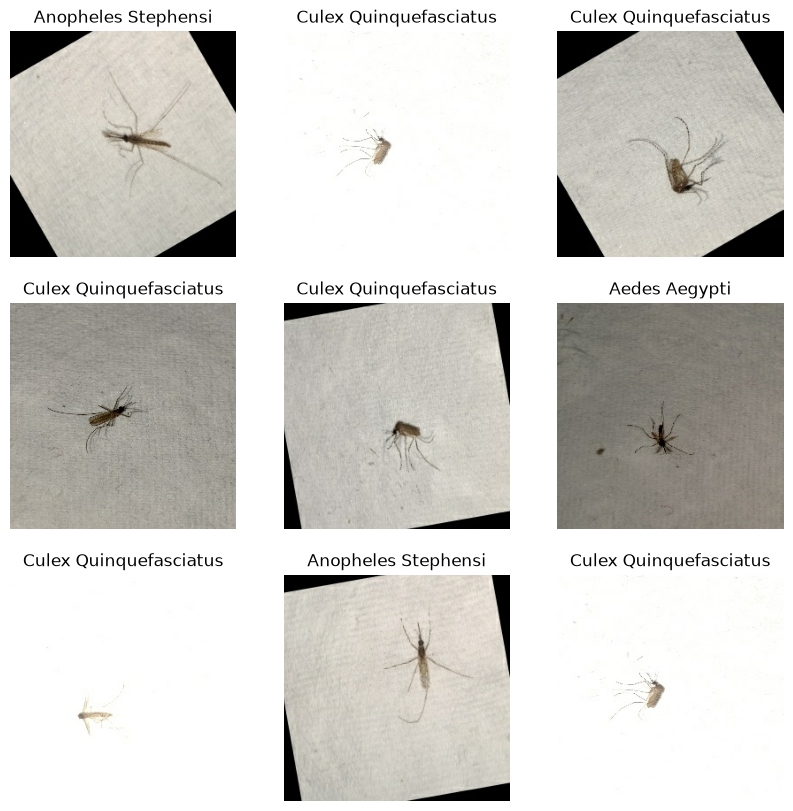

In [ ]:
img_processor.show_sample_image_x_label('train') # Vista de datos para entrenamiento